In [1]:
# Step 1. Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score

import joblib
import os

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import os

print("Current Working Directory:")
print(os.getcwd())

print("\nFiles and Folders:")
print(os.listdir())

Current Working Directory:
C:\Users\Amrit Singh\Desktop\Customer_Segmentation_ML\notebook

Files and Folders:
['.ipynb_checkpoints', 'Customer_Segmentation.ipynb']


In [6]:
import pandas as pd

df = pd.read_csv(r"C:\Users\Amrit Singh\Desktop\Customer_Segmentation_ML\data\Mall_Customers.csv")

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [8]:
# Now check dataset information

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (200, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

Statistical Summary:
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34

In [9]:
# Step 3. Data cleaning

print("Duplicate Records:", df.duplicated().sum())

print("Missing Values:")
print(df.isnull().sum())

Duplicate Records: 0
Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [10]:
# Handle missing values and duplicates

# Remove duplicate records
df = df.drop_duplicates()

# Remove records with missing values
df = df.dropna()

# Check again
print("Final Shape:", df.shape)

Final Shape: (200, 5)


In [11]:
# Remove the CustomerID column from our ML features

print(df.columns.tolist())

['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


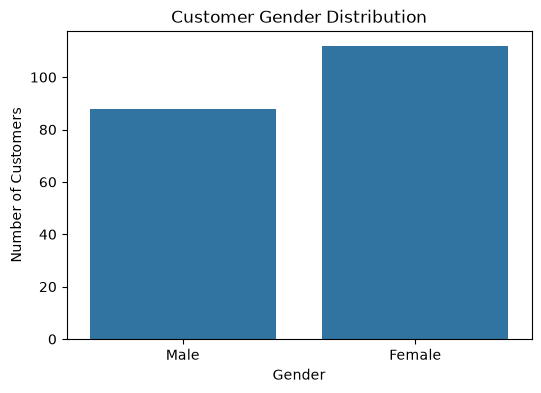

In [12]:
# Step 4. Exploratory Data Analysis (EDA) - EDA means understanding your data using graphs and statistics before applying machine learning.
# 4.1 Gender distribution

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Gender")

plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

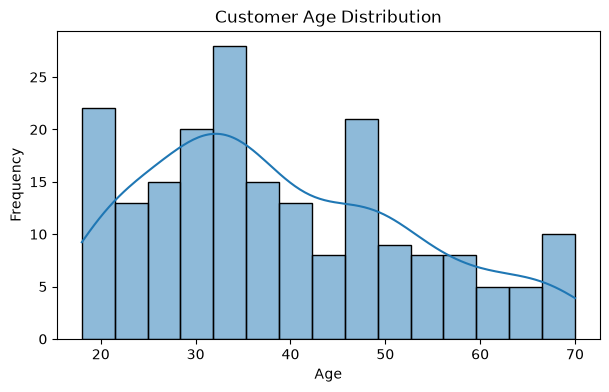

In [14]:
# 4.2 Age distribution

plt.figure(figsize=(7, 4))

sns.histplot(df["Age"], bins=15, kde=True)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

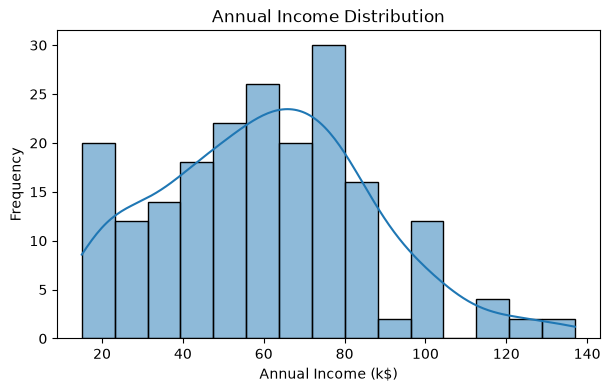

In [15]:
# 4.3 Annual income distribution

plt.figure(figsize=(7, 4))

sns.histplot(df["Annual Income (k$)"], bins=15, kde=True)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Frequency")

plt.show()

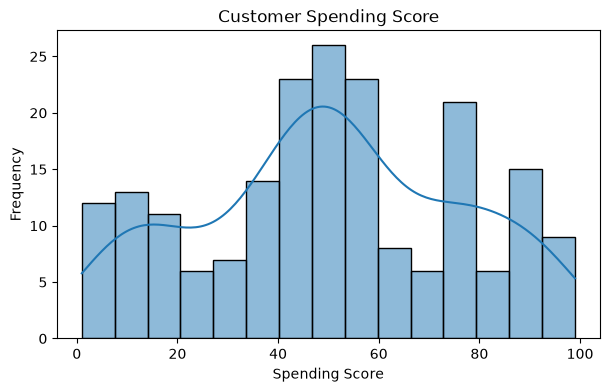

In [16]:
# 4.4 Spending score distribution

plt.figure(figsize=(7, 4))

sns.histplot(df["Spending Score (1-100)"], bins=15, kde=True)

plt.title("Customer Spending Score")
plt.xlabel("Spending Score")
plt.ylabel("Frequency")

plt.show()

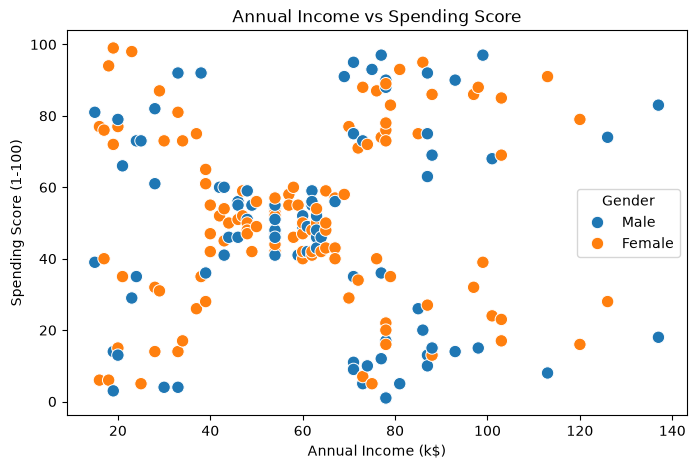

In [17]:
# 4.5 Income vs Spending Score

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Gender",
    s=80
)

plt.title("Annual Income vs Spending Score")

plt.show()

In [20]:
# Step 5. Select features for ML

# We will select two columns:

X = df[
    [
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
]

print(X.head())

# Why are we not using CustomerID?

# Because CustomerID does not tell us anything about spending behaviour.

# Why are we not using Gender and Age?

# To keep the first model simple and focus on income and spending patterns.

   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


In [21]:
# Step 6. Feature scaling

# This is an important ML step.

# Our annual income values and spending scores have different numerical ranges.

# K-Means calculates distances between data points. Therefore, we scale the features so one feature does not dominate simply because of its numerical scale.

# We use StandardScaler.

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


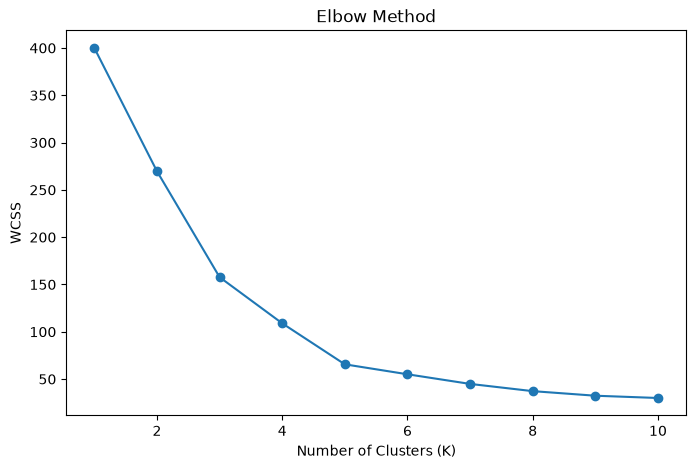

In [23]:
# Step 7. Find the optimal number of clusters

# For this dataset, five clusters are a common starting choice. However, the elbow graph should be inspected rather than assuming five is always optimal.

# How many customer groups should we create?
# Should we create 2, 3, 4, 5 or 6 groups?

# We will use two methods:
# 1. Elbow Method.
# 2. Silhouette Score.

# 7.1 Elbow Method

wcss = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")

plt.show()

K = 2, Silhouette Score = 0.3213
K = 3, Silhouette Score = 0.4666
K = 4, Silhouette Score = 0.4939
K = 5, Silhouette Score = 0.5547
K = 6, Silhouette Score = 0.5399
K = 7, Silhouette Score = 0.5281
K = 8, Silhouette Score = 0.4552
K = 9, Silhouette Score = 0.4571
K = 10, Silhouette Score = 0.4432


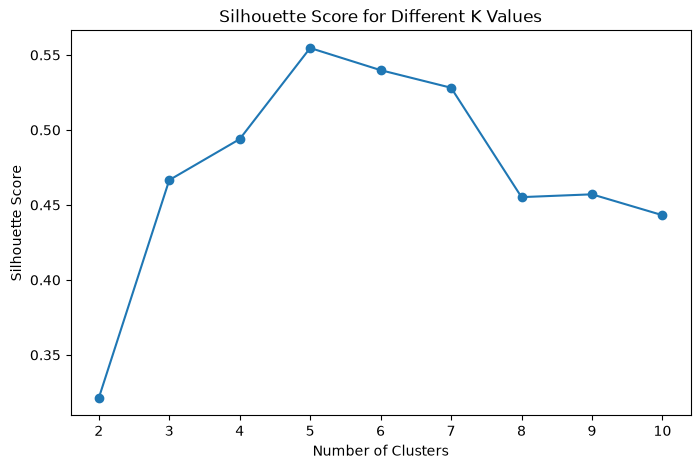

In [24]:
# 7.2 Silhouette Score

# The Silhouette Score measures how well-separated the clusters are. Its range is -1 to +1.

silhouette_scores = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

    print(
        f"K = {k}, Silhouette Score = {score:.4f}"
    )


plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.show()

In [25]:
# Step 8. Train the K-Means model
# Now we will train our actual ML model.

model = Pipeline([
    ("scaler", StandardScaler()),

    ("kmeans", KMeans(n_clusters=5, random_state=42,n_init=10))
])

model.fit(X)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('kmeans', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['Annual Income (k$)','Spending Score (1-100)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


Why are we using Pipeline?

Pipeline combines two operations:
1. StandardScaler scales customer information.
2. KMeans creates customer groups.
Whenever a new customer enters the application, the same scaling operation is automatically applied before prediction.

This is important to avoid using inconsistent preprocessing.

In [28]:
# Step 9. Assign clusters to customers

# Now predict the cluster for every customer.
# The cluster numbers above are illustrative, not guaranteed outputs.

df["Cluster"] = model.predict(X)

print(df.head(10))

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   
5           6  Female   22                  17                      76   
6           7  Female   35                  18                       6   
7           8  Female   23                  18                      94   
8           9    Male   64                  19                       3   
9          10  Female   30                  19                      72   

   Cluster  
0        4  
1        2  
2        4  
3        2  
4        4  
5        2  
6        4  
7        2  
8        4  
9        2  


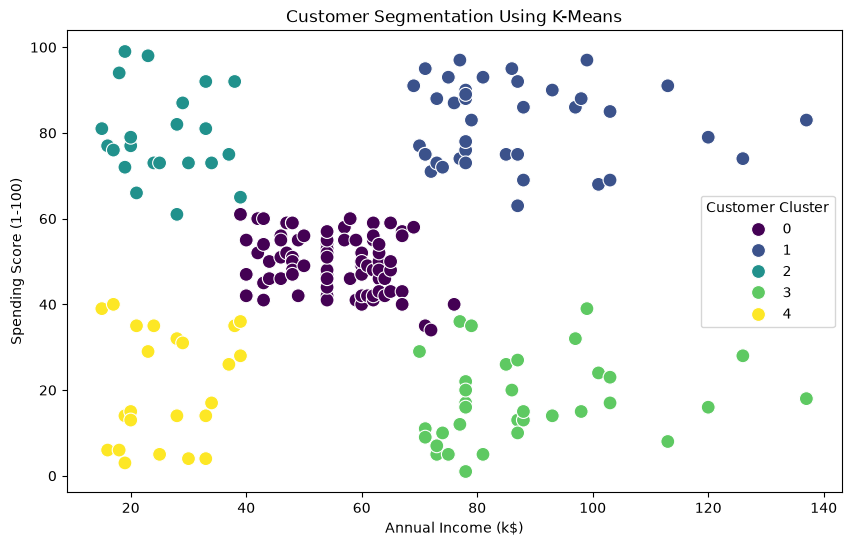

In [29]:
# Step 10. Visualize the customer segments

# This is the most important output of the project.

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    s=100
)

plt.title("Customer Segmentation Using K-Means")

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")

plt.legend(title="Customer Cluster")

plt.show()

In [30]:
# Step 11. Understand each customer segment

# The model gives cluster numbers, but it does not automatically give meaningful names.
# We need to calculate the average income and spending score of each group.

cluster_summary = df.groupby("Cluster").agg({

    "Annual Income (k$)": "mean",

    "Spending Score (1-100)": "mean",

    "CustomerID": "count"

}).rename(columns={

    "CustomerID": "Number of Customers"

})

print(cluster_summary.round(2))

         Annual Income (k$)  Spending Score (1-100)  Number of Customers
Cluster                                                                 
0                     55.30                   49.52                   81
1                     86.54                   82.13                   39
2                     25.73                   79.36                   22
3                     88.20                   17.11                   35
4                     26.30                   20.91                   23


Step 12. Evaluate the ML model

Since K-Means is unsupervised learning, we do not have actual correct cluster labels to calculate normal classification accuracy.
    Instead, we use:
- Silhouette Score: Measures cluster separation.
- Inertia: Measures within-cluster squared distances.
- Cluster size: Shows how customers are distributed.

In [31]:
# Step 12. Evaluate the ML model

final_silhouette = silhouette_score(
    X_scaled,
    model.named_steps["kmeans"].labels_
)

final_inertia = model.named_steps["kmeans"].inertia_

print("Model Evaluation")

print("Silhouette Score:",
      round(final_silhouette, 4))

print("Inertia:",
      round(final_inertia, 4))

print("\nCluster Distribution:")

print(df["Cluster"].value_counts().sort_index())

Model Evaluation
Silhouette Score: 0.5547
Inertia: 65.5684

Cluster Distribution:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [32]:
# Step 13. Save the trained model

# Now we save our trained model so the Streamlit application can use it.

os.makedirs("models", exist_ok=True)

os.makedirs("outputs", exist_ok=True)

# Save the complete pipeline
joblib.dump(
    model,
    "models/customer_segmentation_model.pkl"
)

# Save customer information with cluster labels
df.to_csv(
    "outputs/clustered_customers.csv",
    index=False
)

print("Model saved successfully!")

print("Clustered customer data saved successfully!")

Model saved successfully!
Clustered customer data saved successfully!
